Imports & Setup

In [1]:
import json
import os
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Set clean styling for report-ready plots
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 14,
    'axes.titlesize': 16,
    'figure.autolayout': True
})

print("Libraries loaded successfully!")

Libraries loaded successfully!


Load the COCO Annotations

filtering according to the 10000 ids that we have 

In [ ]:
import json
import os

# 1. Load your team's frozen 10,000 Knowledge Base Image IDs
with open("../data/coco_rag_data/train_kb_ids.json", "r") as f:
    kb_data = json.load(f)
    kb_image_ids = list(kb_data) # Should be exactly 10,000 IDs

# 2. Load full COCO files
ANNOTATIONS_DIR = "../data/annotations_trainval2017/annotations"
with open(os.path.join(ANNOTATIONS_DIR, "captions_train2017.json"), 'r') as f:
    captions_data = json.load(f)

with open(os.path.join(ANNOTATIONS_DIR, "instances_train2017.json"), 'r') as f:
    instances_data = json.load(f)

# 3. FILTER Captions to ONLY include your 10,000 KB images
filtered_captions = [
    ann for ann in captions_data['annotations'] 
    if ann['image_id'] in kb_image_ids
]
## NOTE : 
## since we didnt enforce for now that an image can't have more than 5 captions , it will be more than 50.000 by 29 
## but it's not gonna affect the ditribution of data since 29 is negligible compared to 50.000 
print(f"Total filtered captions: {len(filtered_captions)} (Should be exactly 50,000 , but all images can have more than 5 captions for now (but not less))")

# 4. FILTER Instances/Objects to ONLY include your 10,000 KB images
filtered_instances = [
    ann for ann in instances_data['annotations'] 
    if ann['image_id'] in kb_image_ids
]
print(f"Total filtered object instances: {len(filtered_instances)}")


Total filtered captions: 50029 (Should be exactly 50,000 , but since not all images have 5 captions, it may be more )
Total filtered object instances: 72607


Caption Length Distribution Analysis

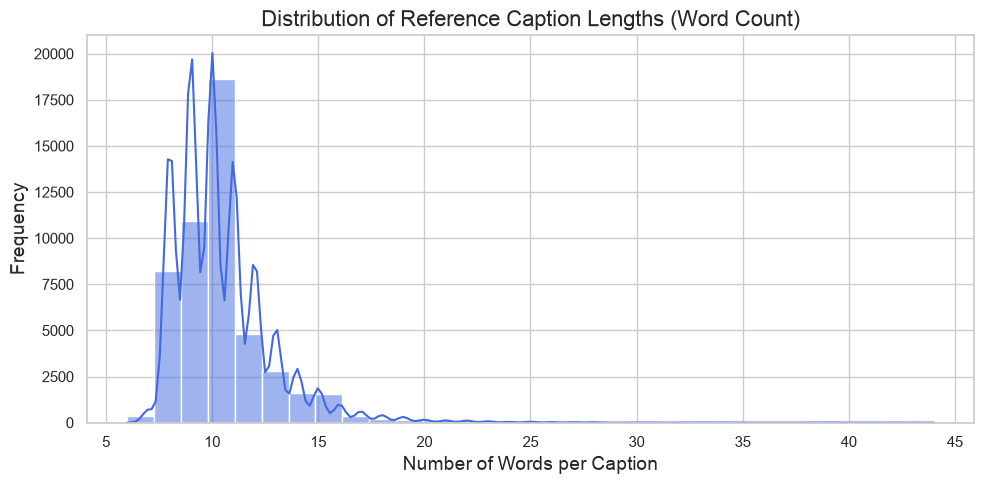

Average caption length: 10.46 words


In [9]:
# Calculate word count for every reference caption
caption_lengths = [len(ann['caption'].split()) for ann in filtered_captions]

# Plotting
plt.figure(figsize=(10, 5))
sns.histplot(caption_lengths, bins=30, kde=True, color='royalblue')
plt.title("Distribution of Reference Caption Lengths (Word Count)")
plt.xlabel("Number of Words per Caption")
plt.ylabel("Frequency")
plt.savefig("caption_length_distribution.png", dpi=300)
plt.show()

print(f"Average caption length: {sum(caption_lengths)/len(caption_lengths):.2f} words")

Top Object Class Frequencies (COCO Categories)

/tmp/ipykernel_239911/662017167.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts, y=names, palette="viridis")


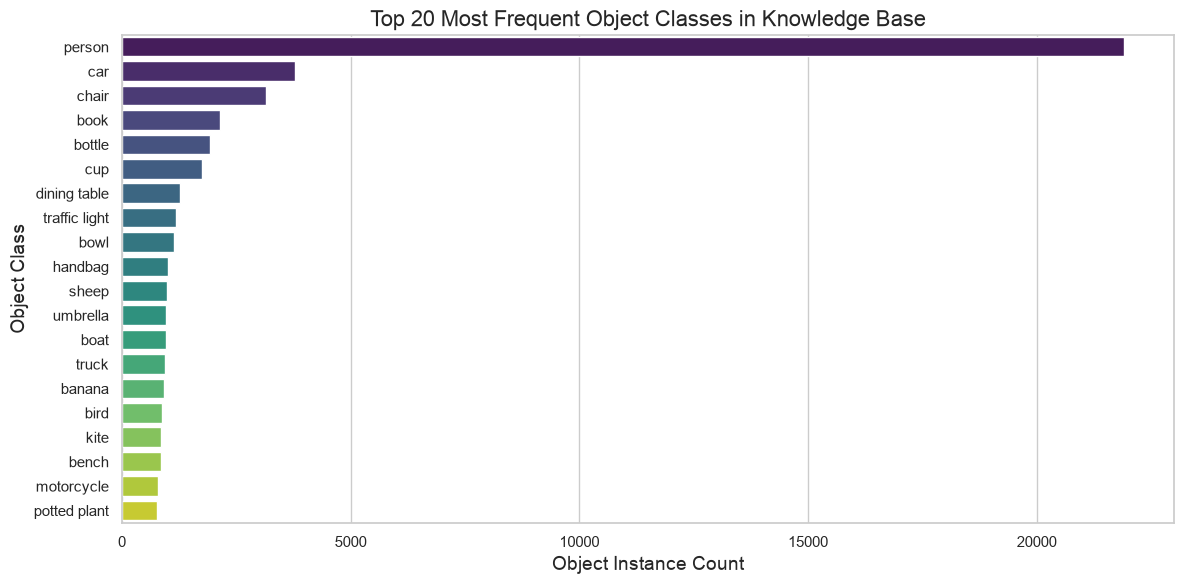

In [6]:
# Map category IDs to names
category_map = {cat['id']: cat['name'] for cat in instances_data['categories']}

# Count object occurrences across annotations
category_counts = Counter([ann['category_id'] for ann in filtered_instances])
top_categories = category_counts.most_common(20) # Top 20 objects

names = [category_map[cat_id] for cat_id, count in top_categories]
counts = [count for cat_id, count in top_categories]

# Plotting Top 20 Objects
plt.figure(figsize=(12, 6))
sns.barplot(x=counts, y=names, palette="viridis")
plt.title("Top 20 Most Frequent Object Classes in Knowledge Base")
plt.xlabel("Object Instance Count")
plt.ylabel("Object Class")
plt.savefig("top_objects_frequency.png", dpi=300)
plt.show()

Cell 5: Scene Complexity (Objects per Image)

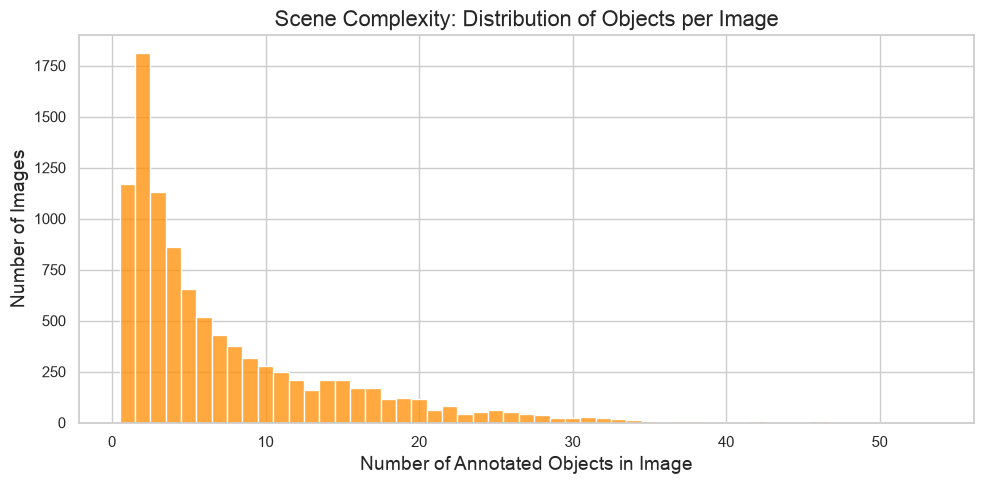

Average objects per image: 7.32


In [7]:
# Count how many objects appear in each image
image_object_counts = Counter([ann['image_id'] for ann in filtered_instances])
objects_per_image_list = list(image_object_counts.values())

# Plotting
plt.figure(figsize=(10, 5))
sns.histplot(objects_per_image_list, bins=range(1, 20), discrete=True, color='darkorange')
plt.title("Scene Complexity: Distribution of Objects per Image")
plt.xlabel("Number of Annotated Objects in Image")
plt.ylabel("Number of Images")
plt.savefig("scene_complexity.png", dpi=300)
plt.show()

print(f"Average objects per image: {sum(objects_per_image_list)/len(objects_per_image_list):.2f}")

Cell 6: Export Summary Statistics CSV

In [10]:
# Create a quick summary dataframe for your report appendix
summary_data = {
    "Metric": [
        "Total Knowledge Base Images",
        "Total Reference Captions",
        "Average Words per Caption",
        "Total Object Categories",
        "Average Objects per Image"
    ],
    "Value": [
        len(kb_image_ids),
        len(filtered_captions),
        round(sum(caption_lengths)/len(caption_lengths), 2),
        category_counts.__len__(),
        round(sum(objects_per_image_list)/len(objects_per_image_list), 2)
    ]
}

df_summary = pd.DataFrame(summary_data)
df_summary.to_csv("dataset_statistics_summary.csv", index=False)
print("Saved summary table to 'dataset_statistics_summary.csv'")
display(df_summary)

Saved summary table to 'dataset_statistics_summary.csv'


,Metric,Value
0,Total Knowledge Base Images,10000.00
1,Total Reference Captions,50029.00
2,Average Words per Caption,10.46
3,Total Object Categories,80.00
4,Average Objects per Image,7.32
